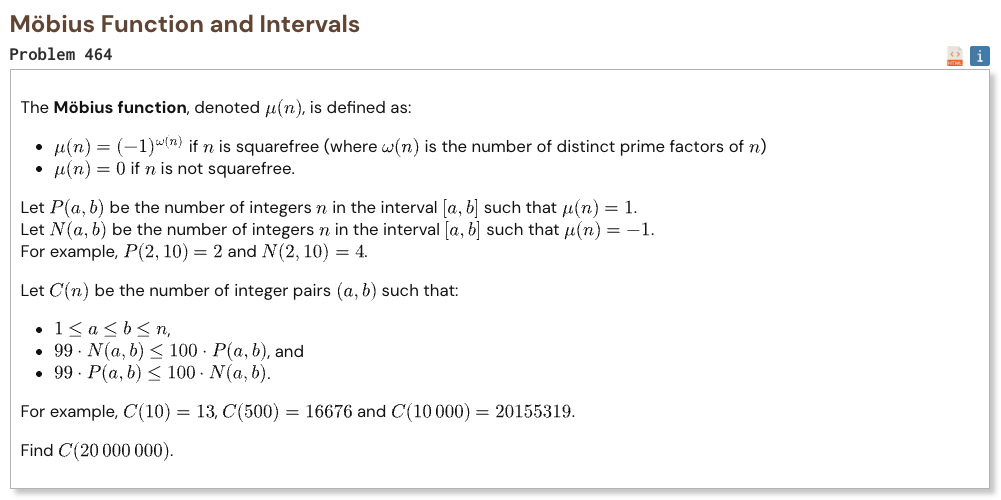

## Initial approach

-   turn the interval condition into a condition on prefix counts of positive and negative Möbius values
-   combine those counts into two prefix sequences so a valid interval means neither sequence moves in the wrong direction
-   an invalid interval must fail in exactly one of those two directions so the two bad cases can be counted separately
-   generate all Möbius values up to twenty million with a sieve instead of factoring every number
-   count increasing prefix pairs with a Fenwick tree rather than checking every interval
-   use numpy for the large Möbius arrays and numba to compile the Fenwick tree loops
-   subtract both bad pair counts from the total number of intervals

In [1]:
%%time

import math
import numpy as np
from numba import njit

N = 20_000_000

def small_primes(limit):
    sieve = np.ones(limit + 1, dtype=np.bool_)
    sieve[:2] = False
    sieve[2:limit + 1:2] = False
    sieve[2] = True

    for p in range(3, math.isqrt(limit) + 1, 2):
        if sieve[p]:
            sieve[p * p:limit + 1:2 * p] = False

    return np.nonzero(sieve)[0]

def mobius_sieve(n):
    mu = np.ones(n + 1, dtype=np.int8)
    mu[0] = 0

    remaining = np.arange(n + 1, dtype=np.int32)
    primes = small_primes(math.isqrt(n))

    for p in primes:
        mu[p::p] *= -1
        mu[p * p::p * p] = 0
        remaining[p::p] //= p

    mu[remaining > 1] *= -1

    return mu

@njit
def count_bad_pairs(mu, positive_step, negative_step):
    value = 0
    minimum = 0
    maximum = 0

    for i in range(1, len(mu)):
        if mu[i] == 1:
            value += positive_step
        elif mu[i] == -1:
            value += negative_step

        if value < minimum:
            minimum = value

        if value > maximum:
            maximum = value

    size = maximum - minimum + 3
    tree = np.zeros(size, dtype=np.int32)

    value = 0
    first_index = value - minimum + 1

    index = first_index

    while index < size:
        tree[index] += 1
        index += index & -index

    result = np.int64(0)

    for i in range(1, len(mu)):
        if mu[i] == 1:
            value += positive_step
        elif mu[i] == -1:
            value += negative_step

        index = value - minimum + 1
        query = index - 1
        count = 0

        while query > 0:
            count += tree[query]
            query -= query & -query

        result += count

        update = index

        while update < size:
            tree[update] += 1
            update += update & -update

    return result

mu = mobius_sieve(N)

bad_positive = count_bad_pairs(mu, 198, -200)
bad_negative = count_bad_pairs(mu, -200, 198)

total_intervals = N * (N + 1) // 2

result = (
    total_intervals
    - bad_positive
    - bad_negative
)

print("Result:", result)

Result: 198775297232878
CPU times: user 1.57 s, sys: 125 ms, total: 1.7 s
Wall time: 3.18 s
